In [10]:
# =========================================
# 📌 SETUP GLOBAL - TACHE 2 (AGE PREDICTION)
# =========================================
#Import des bibliothèques
import os, re, random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Fix seeds
np.random.seed(42)
tf.random.set_seed(42)

print("✅ Setup terminé")


✅ Setup terminé


In [11]:
from google.colab import drive
drive.mount('/content/drive')

# ================================
# DÉZIPPAGE
# ================================

# 1) Chemins projet
BASE_DIR = "/content/drive/MyDrive/ANIP_Challenge"
DATASETS_DIR = f"{BASE_DIR}/Datasets"
WORK_DIR = "/content/data"
!mkdir -p "{WORK_DIR}"

# 2) Fonction de dézippage
import os, zipfile, sys

def safe_unzip(zip_path, dest):
    if not os.path.exists(zip_path):
        print(f"⚠️ zip introuvable: {zip_path}")
        return
    print(f"Unzipping {zip_path} ...")
    !mkdir -p "{dest}"
    !unzip -q "{zip_path}" -d "{dest}"
    content = os.listdir(dest)
    if len(content) == 1 and os.path.isdir(os.path.join(dest, content[0])):
        subfolder = os.path.join(dest, content[0])
        print(f"Détection d'un sous-dossier, déplaçons le contenu...")
        !mv "{subfolder}"/* "{dest}"
        !rmdir "{subfolder}"
    print("Terminé.")

# 3) Nom du fichier ZIP pour la Tâche 2
ZIP_T2 = f"{DATASETS_DIR}/dataset_tache_2.zip"

# 4) Dézippage du dataset de la Tâche 2
safe_unzip(ZIP_T2, f"{WORK_DIR}/tache2")

print("✅ Setup et dézippage terminés")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unzipping /content/drive/MyDrive/ANIP_Challenge/Datasets/dataset_tache_2.zip ...
Détection d'un sous-dossier, déplaçons le contenu...
Terminé.
✅ Setup et dézippage terminés


In [37]:
# =========================================
# 📂 PREPARATION DATASET
# =========================================

TRAIN_DIR = "/content/data/tache2/train"
TEST_DIR = "/content/data/tache2/test"

print("Train existe ?", os.path.exists(TRAIN_DIR))
print("Test existe ?", os.path.exists(TEST_DIR))

# Regex pour parser le nom de fichier
pattern = re.compile(r"^(\d+)_\d+([MF])(\d+)\.jpg$", re.IGNORECASE)

data = []
# On s'assure que le chemin existe avant de lister les fichiers
if os.path.exists(TRAIN_DIR):
    for fname in os.listdir(TRAIN_DIR):
        match = pattern.match(fname)
        if match:
            person_id = match.group(1)
            sex = match.group(2)
            age = int(match.group(3))
            data.append([os.path.join(TRAIN_DIR, fname), sex, age])

# Extraction des informations dans un DataFrame
df = pd.DataFrame(data, columns=["path", "sex", "age"])
print("✅ Dataset préparé :", df.shape)
display(df.head())

Train existe ? True
Test existe ? True
✅ Dataset préparé : (40012, 3)


,path,sex,age
0,/content/data/tache2/train/055656_4F46.JPG,F,46
1,/content/data/tache2/train/295485_06M21.JPG,M,21
2,/content/data/tache2/train/4028_04M19.JPG,M,19
3,/content/data/tache2/train/322783_02M19.JPG,M,19
4,/content/data/tache2/train/128416_0M43.JPG,M,43


                age
count  40012.000000
mean      32.869589
std       10.923139
min       16.000000
25%       23.000000
50%       33.000000
75%       41.000000
max       77.000000


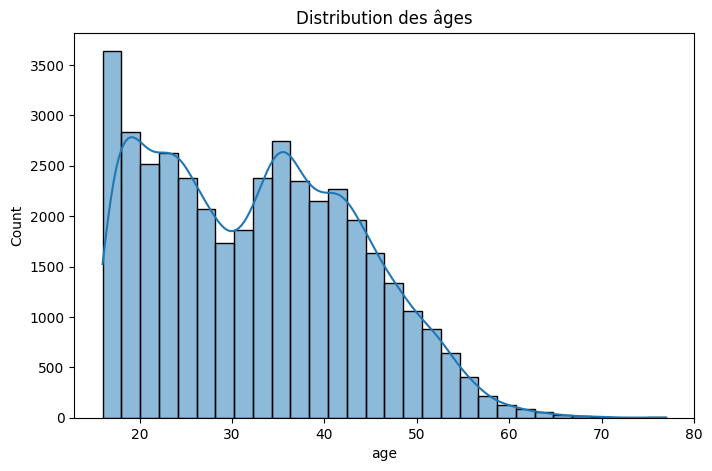

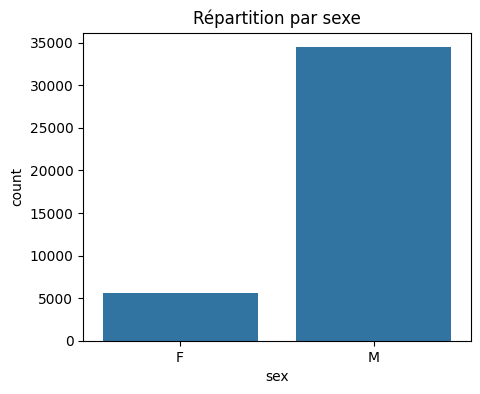

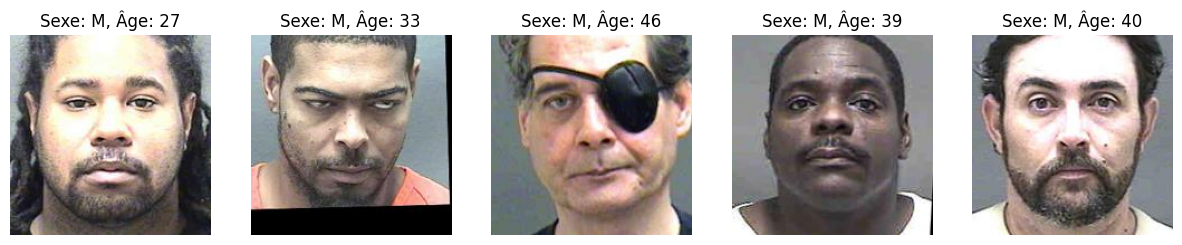

In [13]:
# Analyse Exploratoire
# =========================================
# 📊 EDA
# =========================================

#Info des données d'entrainements
print(df.describe())

#Visualisation
plt.figure(figsize=(8,5))
sns.histplot(df["age"], bins=30, kde=True)
plt.title("Distribution des âges")
plt.show()

plt.figure(figsize=(5,4))
sns.countplot(x="sex", data=df)
plt.title("Répartition par sexe")
plt.show()

# Exemples d'image
def show_random_images(df, n=5):
    sample = df.sample(n)
    plt.figure(figsize=(15, 5))
    for i, (_, row) in enumerate(sample.iterrows()):
        img = cv2.imread(row["path"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(1, n, i+1)
        plt.imshow(img)
        plt.title(f"Sexe: {row['sex']}, Âge: {row['age']}")
        plt.axis("off")
    plt.show()

show_random_images(df)


/tmp/ipython-input-1104034215.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="sex", y="age", data=df, estimator=np.mean, errorbar=None, palette="rocket")


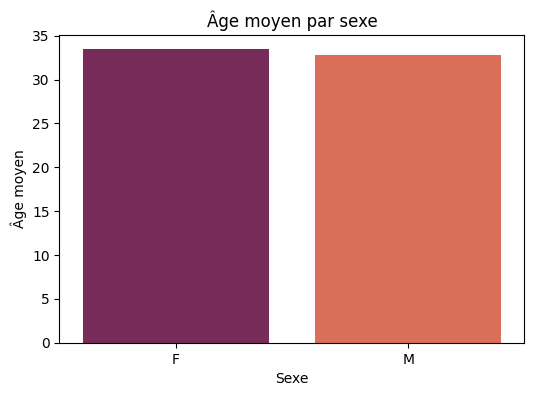

In [14]:
# =========================================
# 📊 ÂGE MOYEN PAR SEXE
# =========================================
plt.figure(figsize=(6, 4))
sns.barplot(x="sex", y="age", data=df, estimator=np.mean, errorbar=None, palette="rocket")
plt.title("Âge moyen par sexe")
plt.xlabel("Sexe")
plt.ylabel("Âge moyen")
plt.show()


In [15]:
# =========================================
# ⚙️ DATA PREPROCESSING
# =========================================

IMG_SIZE = (128,128)
BATCH_SIZE = 32

# Ajout du sexe comme variable numérique
df["sex_num"] = df["sex"].map({"M":0, "F":1})

# Split train/validation
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

# Data Augmentation
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

valgen = ImageDataGenerator(rescale=1./255)

# Générateurs d’images
train_gen = datagen.flow_from_dataframe(
    train_df, x_col="path", y_col="age",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="raw"
)

val_gen = valgen.flow_from_dataframe(
    val_df, x_col="path", y_col="age",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="raw"
)


Found 32009 validated image filenames.
Found 8003 validated image filenames.


In [16]:
# =========================================
# 🤖 MODELE - TRANSFER LEARNING
# =========================================

base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=IMG_SIZE+(3,))
base_model.trainable = False  # On gèle le backbone

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="linear")  # Regression sur âge
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# =========================================
# 🚀 ENTRAINEMENT
# =========================================

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
]

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=callbacks
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
1001/1001 ━━━━━━━━━━━━━━━━━━━━ 734s 723ms/step - loss: 117.0713 - mae: 8.2306 - val_loss: 55.1004 - val_mae: 5.9573
Epoch 2/20
1001/1001 ━━━━━━━━━━━━━━━━━━━━ 664s 663ms/step - loss: 61.7684 - mae: 6.2177 - val_loss: 53.2963 - val_mae: 5.7190
Epoch 3/20
1001/1001 ━━━━━━━━━━━━━━━━━━━━ 654s 653ms/step - loss: 60.7099 - mae: 6.1714 - val_loss: 53.3725 - val_mae: 5.8579
Epoch 4/20
1001/1001 ━━━━━━━━━━━━━━━━━━━━ 643s 642ms/step - loss: 59.9492 - mae: 6.1172 - val_loss: 50.4308 - val_mae: 5.5982
Epoch 5/20
1001/1001 ━━━━━━━━━━━━━━━━━━━━ 638s 637ms/step - loss: 58.8950 - mae: 6.0932 - val_loss: 51.1826 - val_mae: 5.6237
Epoch 6/20
1001/1001 ━━━━━━━━━━━━━━━━━━━━ 687s 686ms/step - loss: 58.3300 - mae: 6.0389 - val_loss: 49.9601 - val_mae: 5.5530
Epoch 7/20
1001/1001 ━━━━━━━━━━━━━━━━━━━━ 662s 661ms/step - loss: 57.3233 - mae: 6.0055 - val_loss: 54.6498 - val_mae: 5.9290
Epoch 8/20
1001/1001 ━━━━━━━━━━━━━━━━━━━━ 694s 694ms/step - loss: 57.7661 - mae: 6.0399 - val_loss: 51.2304 - val_mae

In [30]:
from tensorflow.keras.models import load_model
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.metrics import MeanAbsoluteError

# Remonte ton Drive si nécessaire
from google.colab import drive
drive.mount('/content/drive')

# Redéfinir les objets personnalisés
custom_objects = {
    "mse": MeanSquaredError(),
    "mae": MeanAbsoluteError()
}

# Charger ton modèle avec custom_objects
model = load_model(
    "/content/drive/MyDrive/ANIP_Challenge/model_tache2_best.h5",
    custom_objects=custom_objects
)

print("✅ Modèle rechargé avec succès et prêt à être utilisé")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


✅ Modèle rechargé avec succès et prêt à être utilisé


In [42]:
## Prédictions et Evaluations

from scipy.signal import savgol_filter


# ================================
# 🔹 Chemins
# ================================
BASE_DIR = "/content/drive/MyDrive/ANIP_Challenge"
CSV_OUTPUT = f"{BASE_DIR}/predictions_tache2_final.csv"
REPORT_OUTPUT = f"{BASE_DIR}/predictions_tache2_report.csv"

# ================================
# 🔹 Préparer le test generator
# ================================
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Comme on n'a pas de labels, class_mode=None
test_datagen = ImageDataGenerator(rescale=1./255)

# Créer DataFrame du test set
test_filenames = sorted(os.listdir(TEST_DIR))  # tri pour garder 0-199
test_df = pd.DataFrame({
    "path": [os.path.join(TEST_DIR, f) for f in test_filenames],
    "filename": test_filenames
})

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col="path",
    y_col=None,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode=None,
    shuffle=False
)

# ================================
# 🔹 Prédictions
# ================================
predictions = model.predict(test_generator).flatten()
print("✅ Prédictions brutes générées")

# ================================
# 🔹 Lissage pour réduire bruit et extrêmes
# ================================
predictions_smoothed = savgol_filter(predictions, window_length=5, polyorder=2)
print("✅ Lissage appliqué")

# ================================
# 🔹 Générer CSV final
# ================================
results_df = pd.DataFrame({
    "filename": test_df["filename"],
    "predicted_age": predictions_smoothed
})

results_df.to_csv(CSV_OUTPUT, index=False)
print(f"✅ CSV sauvegardé : {CSV_OUTPUT}")

# ================================
# 🔹 Calcul des statistiques
# ================================
age_mean = np.mean(predictions_smoothed)
age_min = np.min(predictions_smoothed)
age_max = np.max(predictions_smoothed)
age_std = np.std(predictions_smoothed)

report_df = pd.DataFrame({
    "Nombre d'images": [len(predictions_smoothed)],
    "Âge moyen prédit": [age_mean],
    "Âge min": [age_min],
    "Âge max": [age_max],
    "Écart-type des âges prédits": [age_std]
})

report_df.to_csv(REPORT_OUTPUT, index=False)
print(f"✅ Rapport statistique sauvegardé : {REPORT_OUTPUT}")

# ================================
# 🔹 Affichage rapide
# ================================
print("\n--- Statistiques finales ---")
print(report_df)

Found 200 validated image filenames.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/usr/local/lib/python3.12/dist-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 538ms/step
✅ Prédictions brutes générées
✅ Lissage appliqué
✅ CSV sauvegardé : /content/drive/MyDrive/ANIP_Challenge/predictions_tache2_final.csv
✅ Rapport statistique sauvegardé : /content/drive/MyDrive/ANIP_Challenge/predictions_tache2_report.csv

--- Statistiques finales ---
   Nombre d'images  Âge moyen prédit   Âge min    Âge max  \
0              200         31.269341  16.24408  47.278847   

   Écart-type des âges prédits  
0                     5.911238  
